# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [5]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "run.py").exists():
    os.chdir(Path.cwd().parent)

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown, HTML

def compute_metrics(trades_df, stock_df):
    """Compute Max DD, Alpha (vs S&P 500), Sharpe Ratio, and Win Rate."""
    
    portfolio_values = trades_df['portfolio_value'].values
    
    # --- Max Drawdown ---
    running_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (running_max - portfolio_values) / running_max
    max_dd = np.max(drawdowns) * 100
    
    # --- Total Return ---
    initial_val = portfolio_values[0]
    final_val = portfolio_values[-1]
    total_return = (final_val - initial_val) / initial_val
    
    # --- Alpha (vs S&P 500 benchmark) ---
    dates = pd.to_datetime(trades_df['date'])
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    sp500_annual_return = 0.10
    sp500_period_return = (1 + sp500_annual_return) ** n_years - 1
    alpha = (total_return - sp500_period_return) * 100
    
    # --- Sharpe Ratio (annualized, weekly data, 0% risk-free) ---
    weekly_returns = np.diff(portfolio_values) / portfolio_values[:-1]
    if np.std(weekly_returns) > 0:
        sharpe = (np.mean(weekly_returns) / np.std(weekly_returns)) * np.sqrt(52)
    else:
        sharpe = 0.0
    
    # --- Win Rate (only count trades where shares > 0) ---
    real_buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)]
    real_sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)]
    
    wins = 0
    total_trades = 0
    buy_prices = []
    avg_entry = None
    prev_action = None
    
    for _, row in trades_df.iterrows():
        if row['action'] == 'BUY' and row['shares'] > 0:
            if prev_action != 'BUY':
                buy_prices = []
            buy_prices.append(row['price'])
            avg_entry = np.mean(buy_prices)
            prev_action = 'BUY'
        elif row['action'] == 'SELL' and row['shares'] > 0 and avg_entry is not None:
            if row['price'] > avg_entry:
                wins += 1
            total_trades += 1
            prev_action = 'SELL'
    
    win_rate = (wins / total_trades * 100) if total_trades > 0 else 0.0
    
    return {
        'max_dd': max_dd,
        'alpha': alpha,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'total_return': total_return * 100,
        'final_val': final_val,
        'n_buys': len(real_buys),
        'n_sells': len(real_sells),
        'total_trades': total_trades,
        'wins': wins
    }


def build_trade_log(trades_df):
    """Build a styled trade log table showing only executed BUY/SELL (shares > 0)."""
    # Filter to only executed trades (shares > 0)
    active = trades_df[
        (trades_df['action'].isin(['BUY', 'SELL'])) & (trades_df['shares'] > 0)
    ].copy()
    active = active.reset_index(drop=True)
    
    # Format columns
    log = pd.DataFrame()
    log['Date'] = pd.to_datetime(active['date']).dt.strftime('%Y-%m-%d')
    log['Action'] = active['action']
    log['Price'] = active['price'].map('${:,.2f}'.format)
    log['Shares'] = active['shares'].map('{:,.0f}'.format)
    log['Value'] = active['value'].map('${:,.2f}'.format)
    log['Portfolio'] = active['portfolio_value'].map('${:,.2f}'.format)
    
    return log


def style_trade_log(log):
    """Apply color styling to the trade log."""
    def color_action(val):
        if val == 'BUY':
            return 'color: #00c853; font-weight: bold'
        elif val == 'SELL':
            return 'color: #ff1744; font-weight: bold'
        return ''
    
    styled = log.style.applymap(
        color_action, subset=['Action']
    ).set_properties(**{
        'text-align': 'right',
        'font-size': '12px',
        'padding': '4px 8px',
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2d2d44'),
            ('color', 'white'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '6px 10px'),
        ]},
        {'selector': 'td', 'props': [
            ('border-bottom', '1px solid #444'),
        ]},
    ]).hide(axis='index')
    
    return styled


def plot_ticker(ticker, method='DQN'):
    """Plot candlestick chart with buy/sell arrows and trade log."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_weekly_stock_data.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Compute performance metrics ---
    metrics = compute_metrics(trades_df, stock_df)
    
    # --- Extract only EXECUTED BUY and SELL trades (shares > 0) ---
    buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)].copy()
    sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)].copy()
    
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Title with core stats ---
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {metrics["total_return"]:+.1f}%  |  '
             f'Final: ${metrics["final_val"]:,.0f}  |  '
             f'Buys: {metrics["n_buys"]}  |  Sells: {metrics["n_sells"]}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 10),
        tight_layout=False, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    # --- Metrics box below the chart ---
    metrics_text = (
        f'Max DD: {metrics["max_dd"]:.1f}%    '
        f'Alpha (vs S&P): {metrics["alpha"]:+.1f}%    '
        f'Sharpe: {metrics["sharpe"]:.2f}    '
        f'Win Rate: {metrics["win_rate"]:.0f}% '
        f'({metrics["wins"]}/{metrics["total_trades"]} trades)'
    )
    
    fig.text(
        0.5, 0.01, metrics_text,
        ha='center', va='bottom', fontsize=13,
        color='white', fontweight='bold',
        fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2d2d44',
                  edgecolor='#555', alpha=0.9)
    )
    
    fig.subplots_adjust(bottom=0.08)
    plt.show()
    
    # --- Trade Log Table ---
    display(Markdown(f'### {ticker} — Trade Log ({method.replace("_", " ")})'))
    log = build_trade_log(trades_df)
    display(style_trade_log(log))


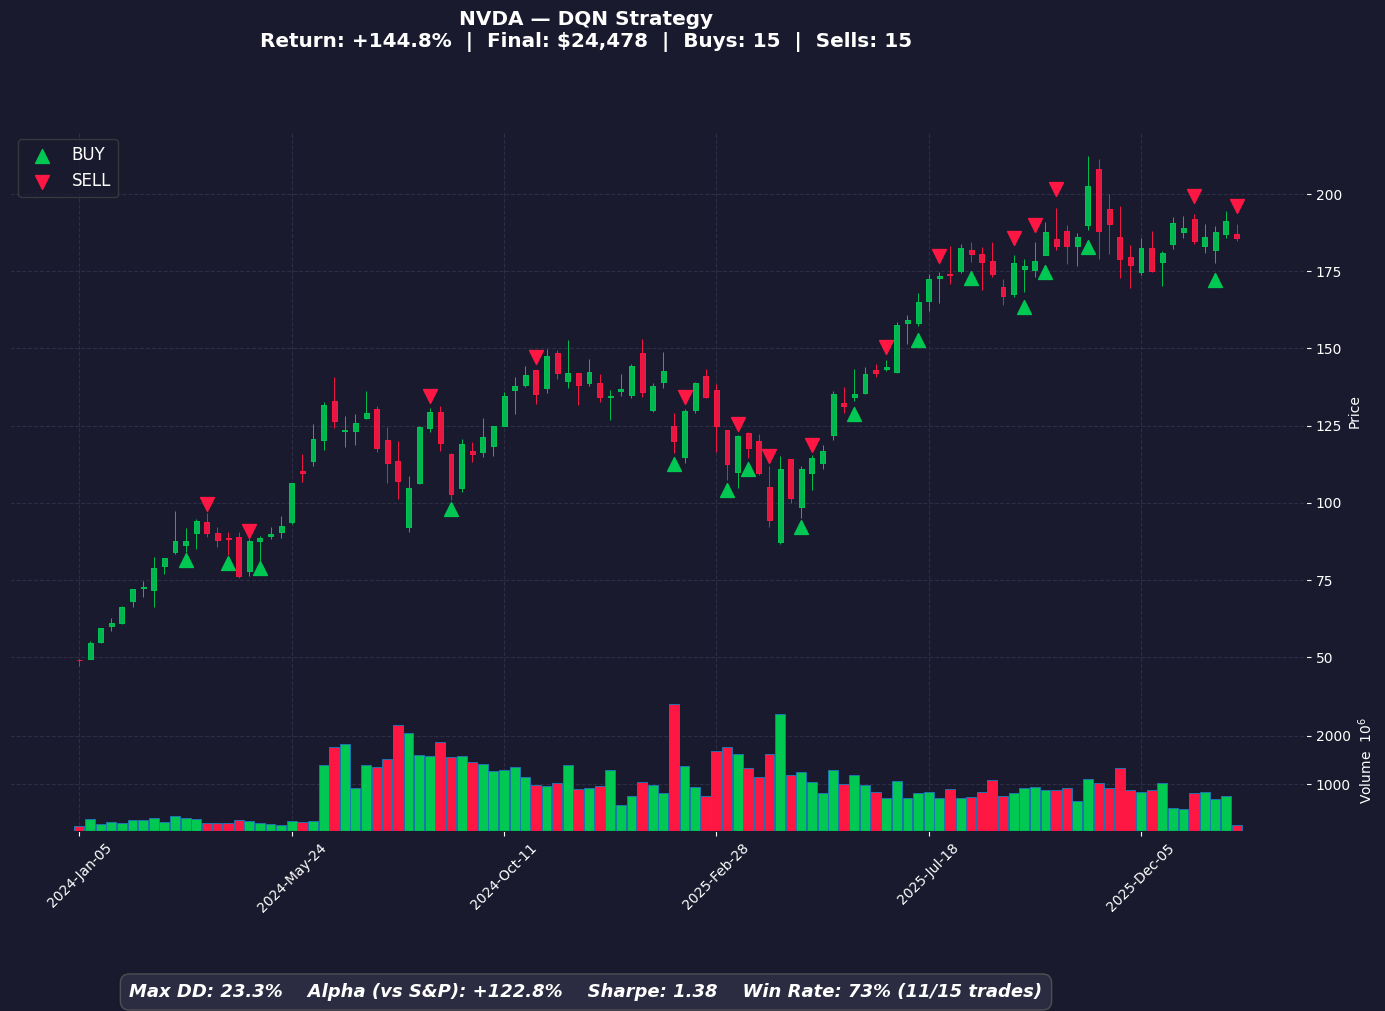

### NVDA — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-03-18,BUY,$88.41,112,"$9,901.98","$9,990.10"
2024-03-25,SELL,$94.95,112,"$10,634.87","$10,712.36"
2024-04-15,BUY,$85.96,124,"$10,658.76","$10,701.70"
2024-04-29,SELL,$87.71,124,"$10,876.40","$10,908.46"
2024-05-06,BUY,$92.09,118,"$10,867.05","$10,897.59"
2024-08-26,SELL,$126.41,118,"$14,916.01","$14,931.63"
2024-09-09,BUY,$106.43,140,"$14,899.54","$14,916.73"
2024-11-04,SELL,$136.00,140,"$19,040.60","$19,038.75"
2025-02-03,BUY,$116.63,163,"$19,010.50","$19,019.74"
2025-02-10,SELL,$133.53,163,"$21,766.09","$21,753.57"


In [6]:
plot_ticker('NVDA', method='DQN')

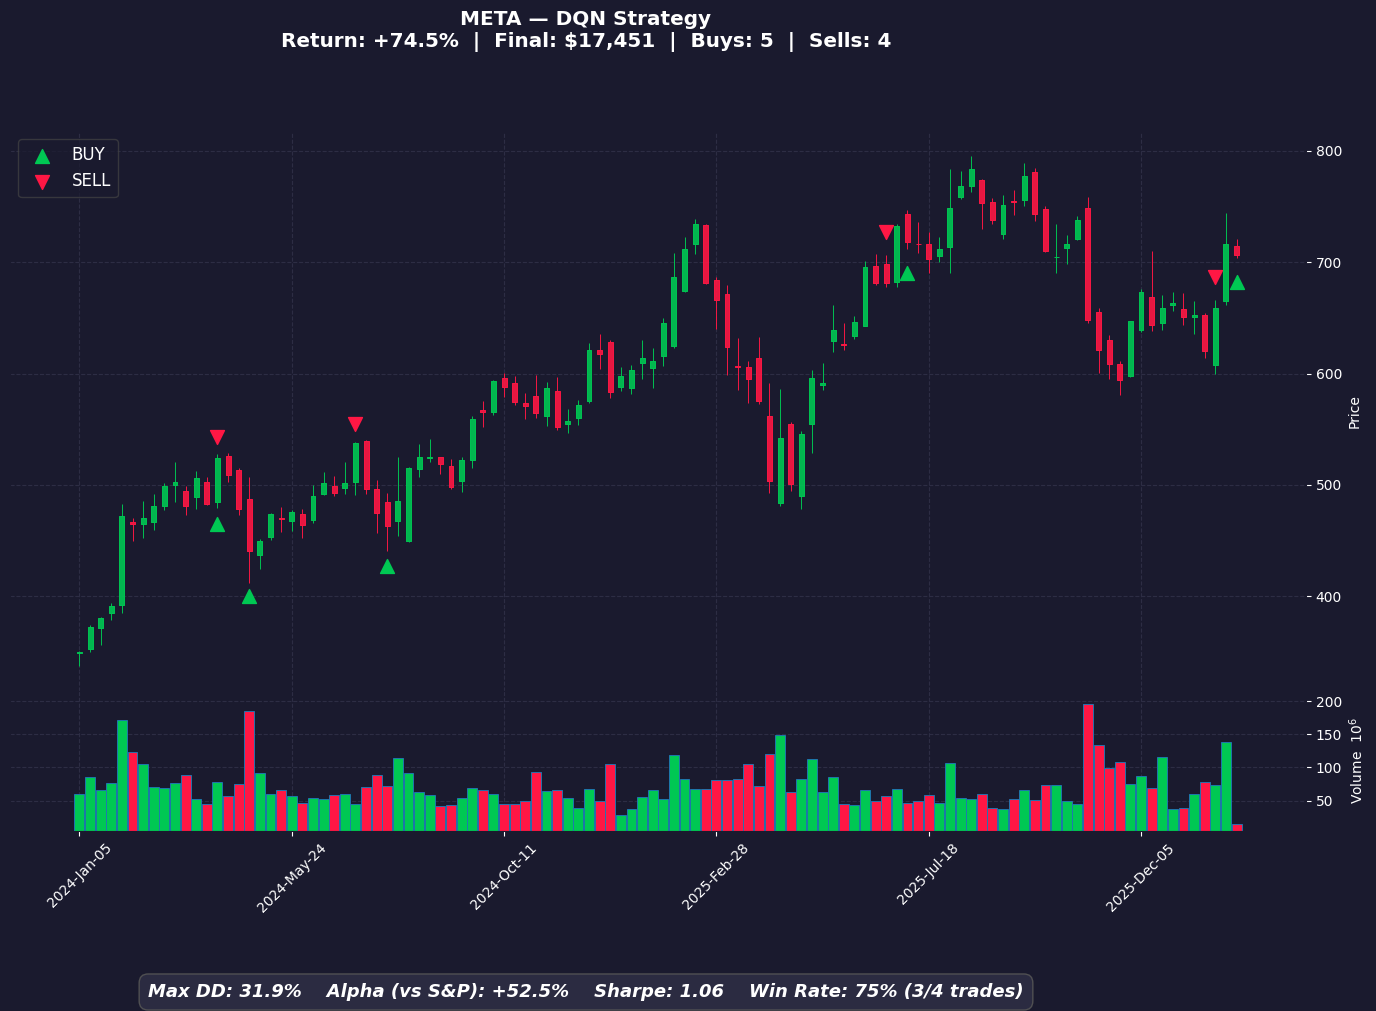

### META — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-04-01,BUY,$488.49,20,"$9,769.81","$9,990.23"
2024-04-08,SELL,$516.23,20,"$10,324.56","$10,534.66"
2024-04-29,BUY,$430.10,24,"$10,322.46","$10,524.34"
2024-07-08,SELL,$526.76,24,"$12,642.28","$12,831.51"
2024-07-29,BUY,$463.46,27,"$12,513.39","$12,819.00"
2025-06-23,SELL,$697.49,27,"$18,832.11","$19,118.89"
2025-06-30,BUY,$736.99,25,"$18,424.66","$19,100.46"
2026-01-26,SELL,$672.36,25,"$16,809.00","$17,467.99"
2026-02-02,BUY,$706.41,24,"$16,953.84","$17,451.04"


In [7]:
plot_ticker('META', method='DQN')

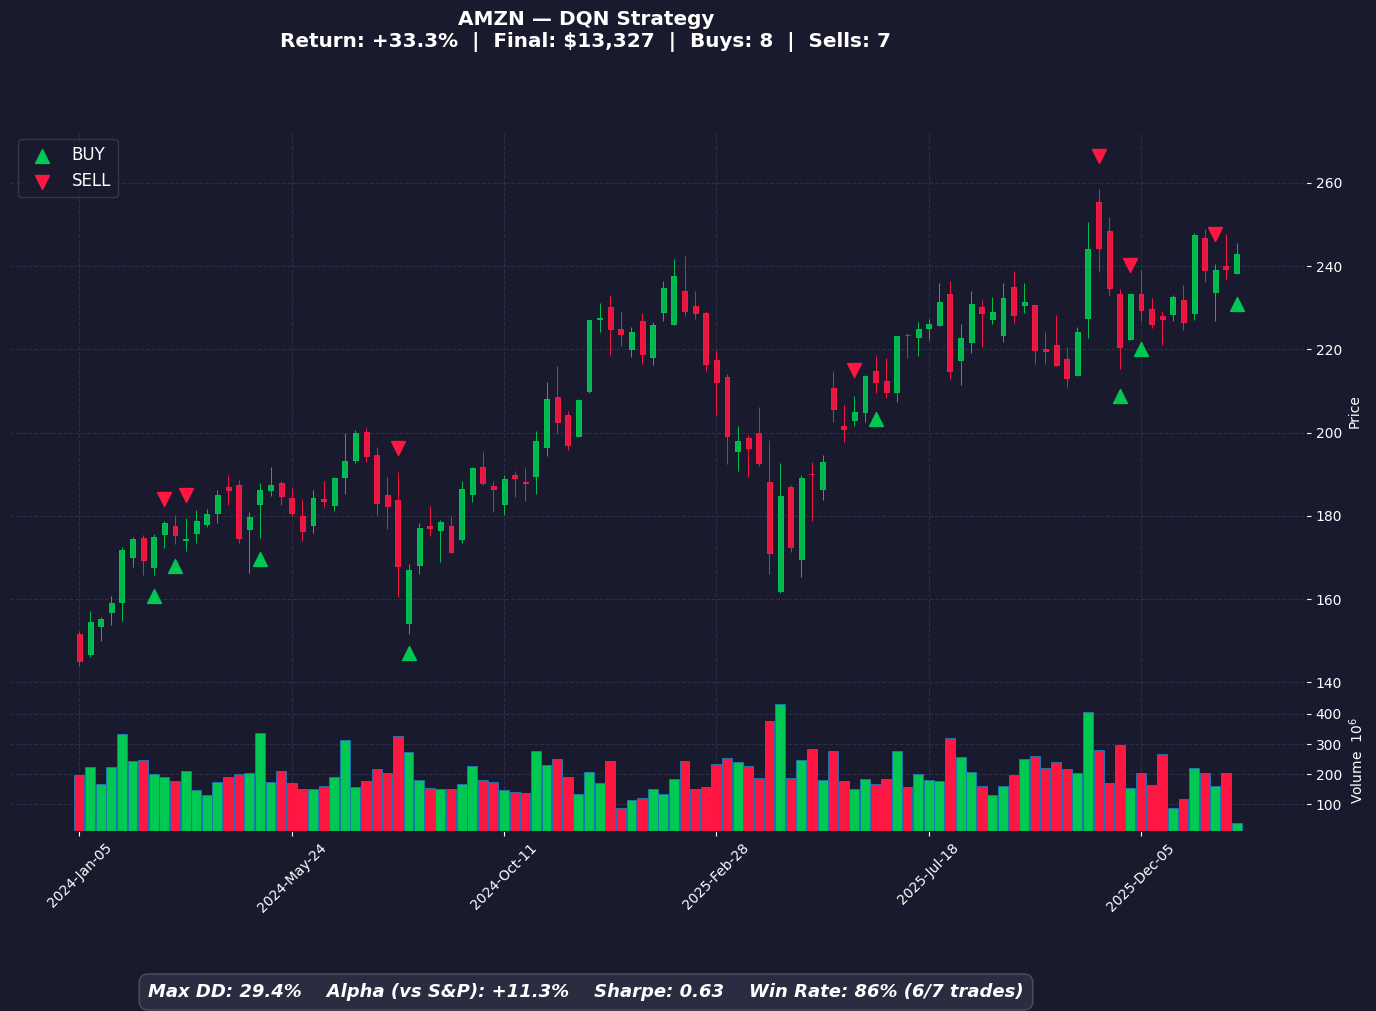

### AMZN — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$174.73,57,"$9,959.61","$9,990.04"
2024-03-04,SELL,$177.58,57,"$10,122.06","$10,142.37"
2024-03-11,BUY,$171.96,58,"$9,973.68","$10,132.39"
2024-03-18,SELL,$174.48,58,"$10,119.84","$10,268.43"
2024-05-06,BUY,$188.70,54,"$10,189.80","$10,258.25"
2024-08-05,SELL,$161.02,54,"$8,695.08","$8,754.83"
2024-08-12,BUY,$166.80,52,"$8,673.60","$8,746.16"
2025-05-27,SELL,$206.02,52,"$10,713.04","$10,774.88"
2025-06-16,BUY,$216.10,49,"$10,588.90","$10,764.29"
2025-11-10,SELL,$248.40,49,"$12,171.60","$12,334.82"


In [8]:
plot_ticker('AMZN', method='DQN')

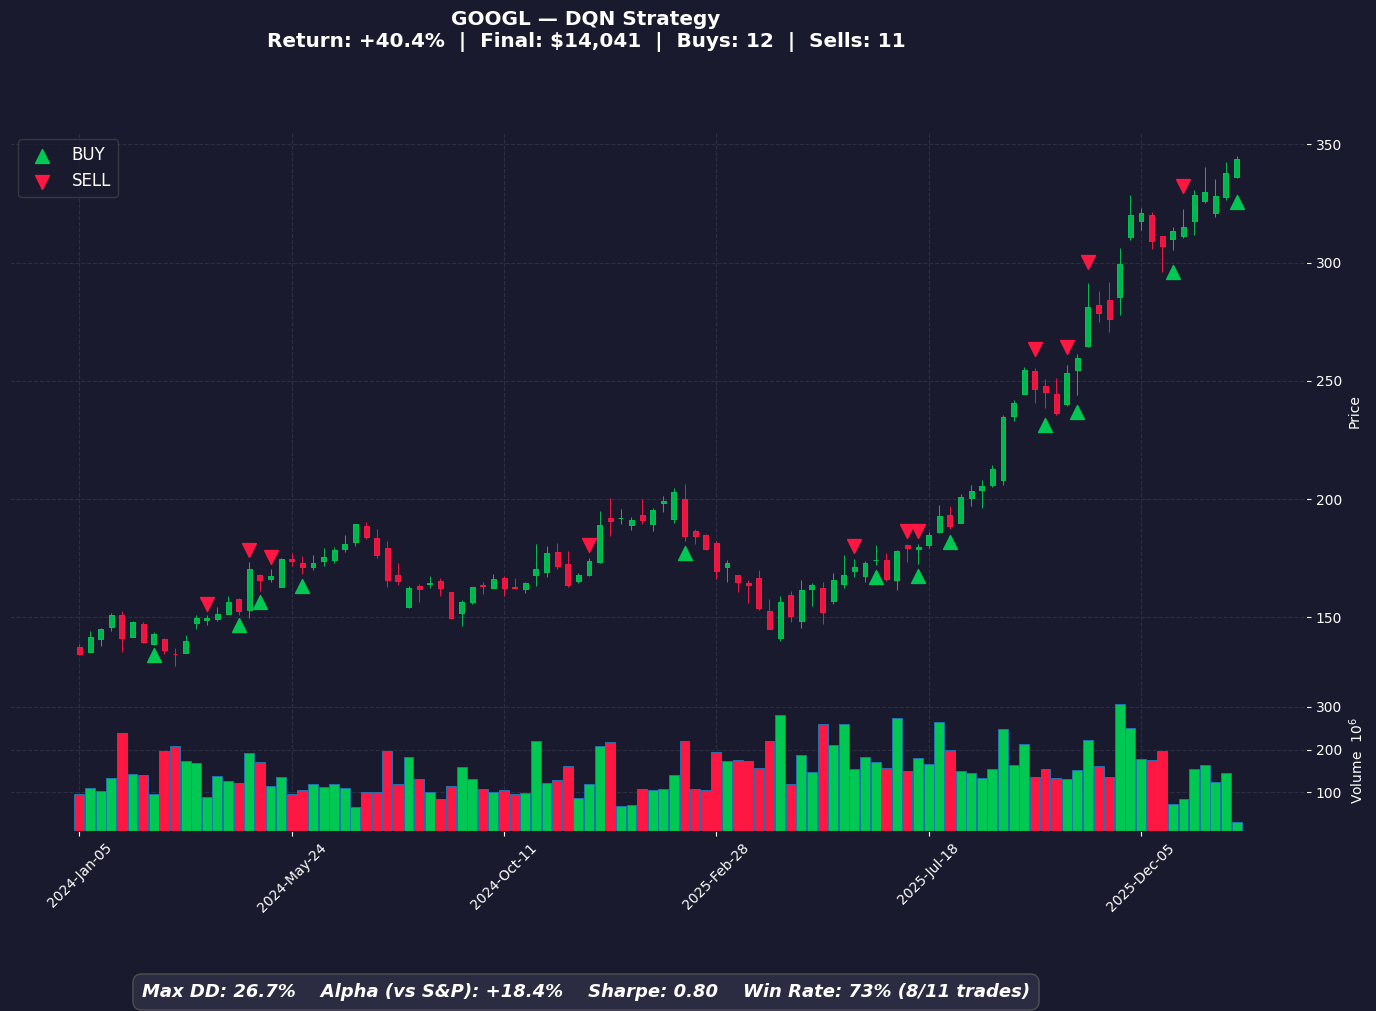

### GOOGL — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$140.05,71,"$9,943.77","$9,990.06"
2024-03-25,SELL,$148.94,71,"$10,574.42","$10,610.13"
2024-04-22,BUY,$155.10,68,"$10,546.70","$10,599.58"
2024-04-29,SELL,$164.89,68,"$11,212.78","$11,254.45"
2024-05-06,BUY,$166.83,67,"$11,177.55","$11,243.28"
2024-05-13,SELL,$167.86,67,"$11,246.71","$11,301.18"
2024-05-28,BUY,$175.07,64,"$11,204.25","$11,289.98"
2024-12-09,SELL,$174.68,64,"$11,179.29","$11,253.84"
2025-02-10,BUY,$185.73,60,"$11,143.95","$11,242.70"
2025-06-02,SELL,$168.56,60,"$10,113.87","$10,202.50"


In [9]:
plot_ticker('GOOGL', method='DQN')

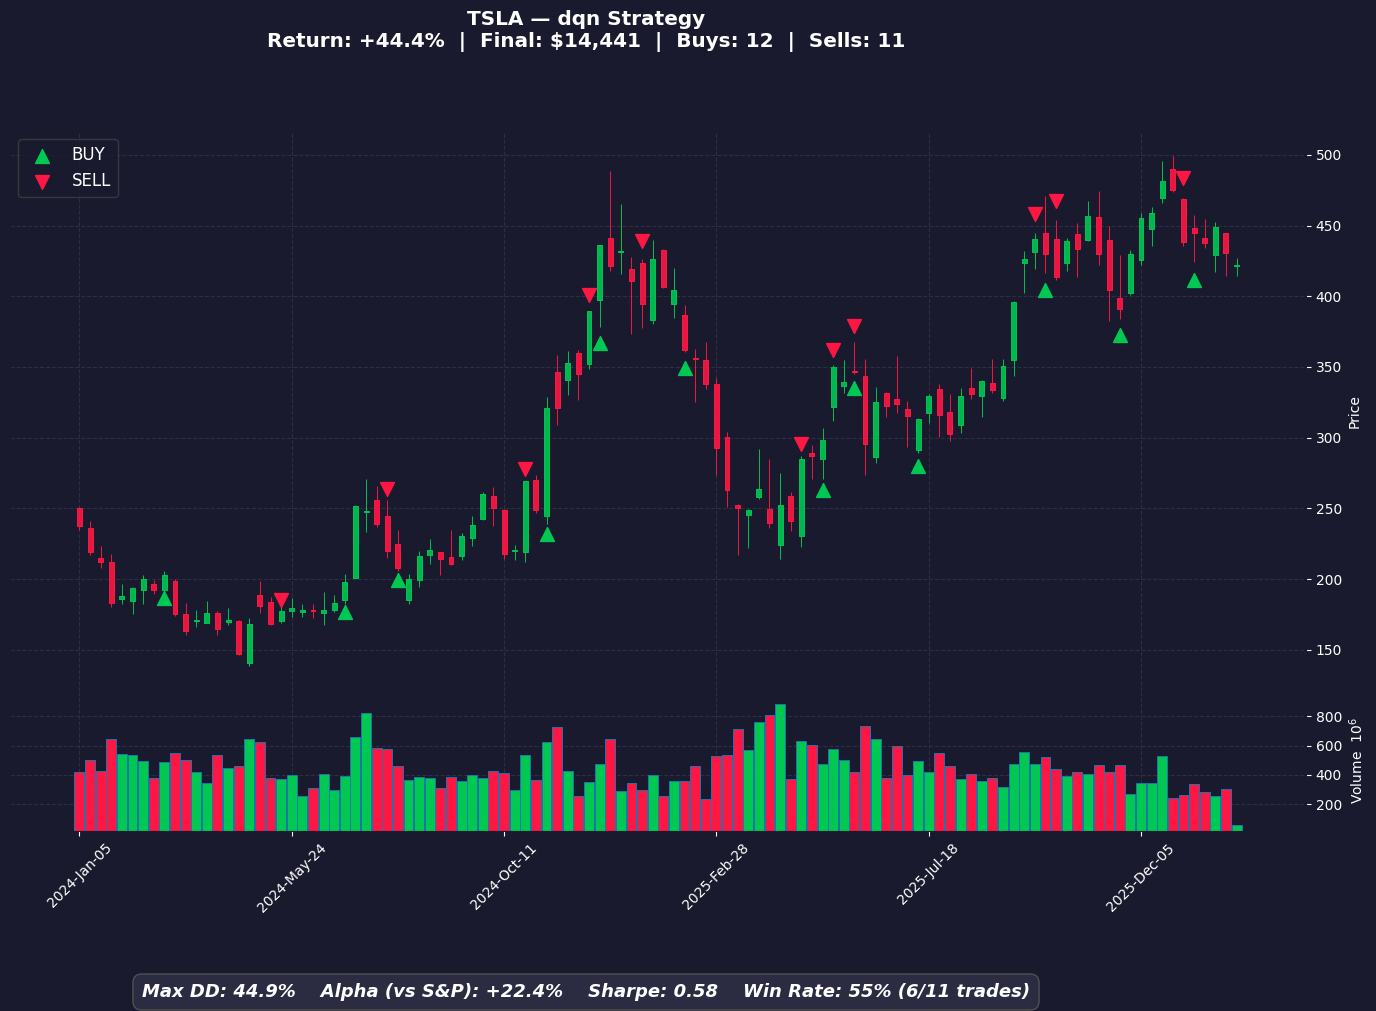

### TSLA — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-03-04,BUY,$188.14,53,"$9,971.42","$9,990.03"
2024-05-20,SELL,$174.95,53,"$9,272.35","$9,281.69"
2024-07-01,BUY,$209.86,44,"$9,233.84","$9,272.45"
2024-07-29,SELL,$232.10,44,"$10,212.40","$10,240.80"
2024-08-05,BUY,$198.88,51,"$10,142.88","$10,230.66"
2024-10-28,SELL,$262.51,51,"$13,388.01","$13,462.40"
2024-11-11,BUY,$350.00,38,"$13,300.00","$13,449.10"
2024-12-09,SELL,$389.79,38,"$14,812.02","$14,946.31"
2024-12-16,BUY,$463.02,32,"$14,816.64","$14,931.49"
2025-01-13,SELL,$403.31,32,"$12,905.92","$13,007.86"


In [10]:
plot_ticker('TSLA', method='dqn')

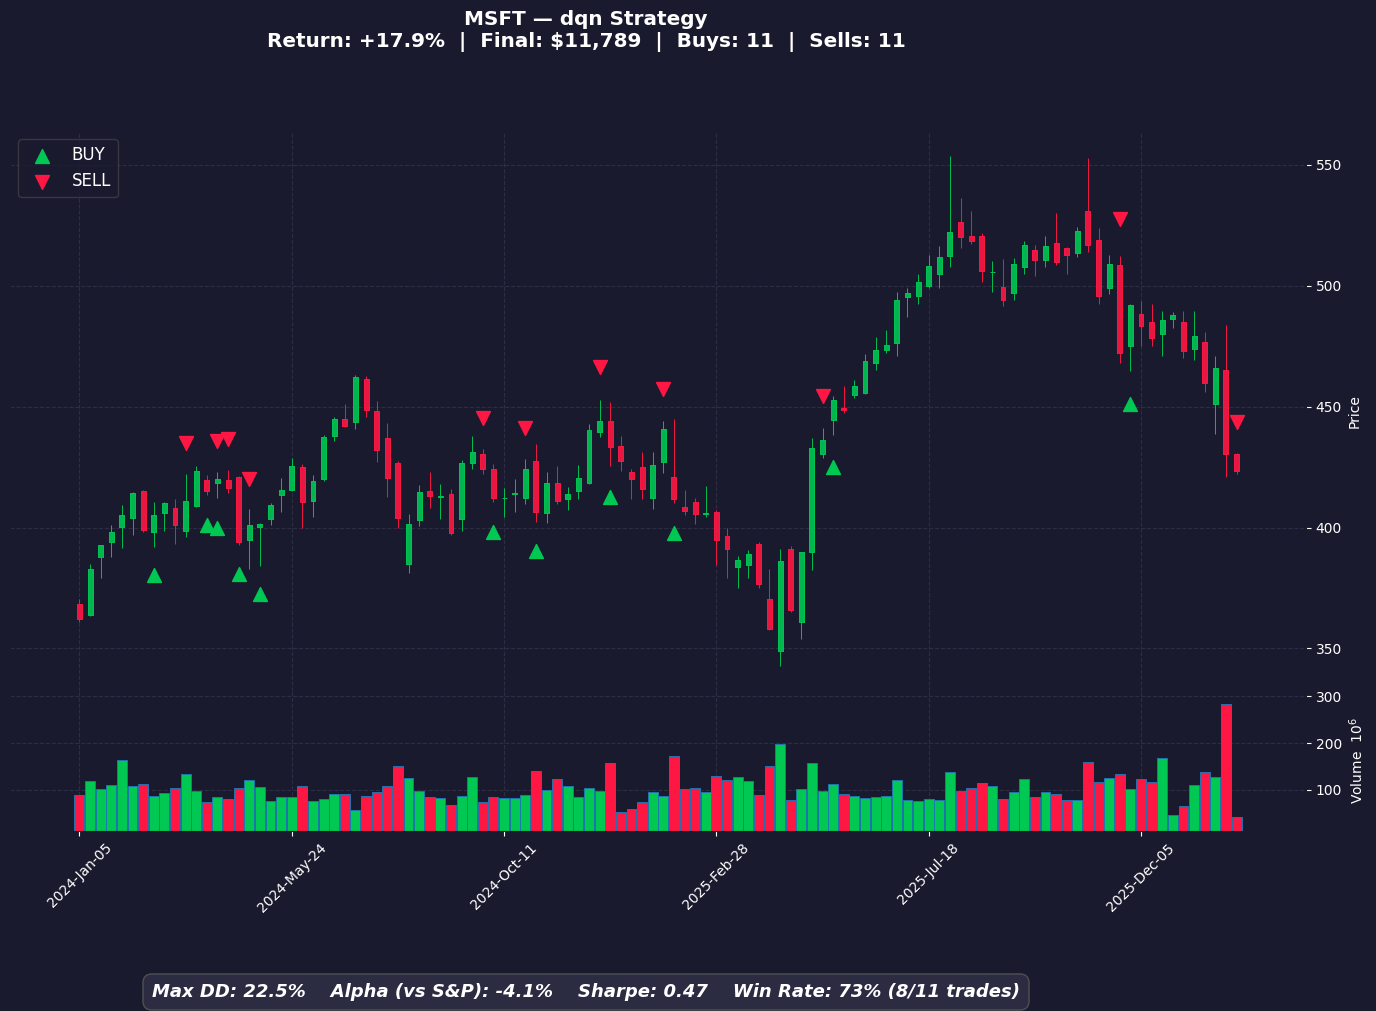

### MSFT — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$397.62,25,"$9,940.42","$9,990.06"
2024-03-18,SELL,$411.96,25,"$10,299.00","$10,338.35"
2024-03-25,BUY,$417.43,24,"$10,018.30","$10,328.33"
2024-04-01,SELL,$419.12,24,"$10,058.81","$10,358.78"
2024-04-08,BUY,$419.14,24,"$10,059.28","$10,348.72"
2024-04-15,SELL,$408.33,24,"$9,799.86","$10,079.50"
2024-04-22,BUY,$395.81,25,"$9,895.26","$10,069.60"
2024-04-29,SELL,$397.08,25,"$9,927.09","$10,091.51"
2024-05-06,BUY,$408.23,24,"$9,797.49","$10,081.71"
2024-09-30,SELL,$426.28,24,"$10,230.83","$10,504.82"


In [11]:
plot_ticker('MSFT', method='dqn')

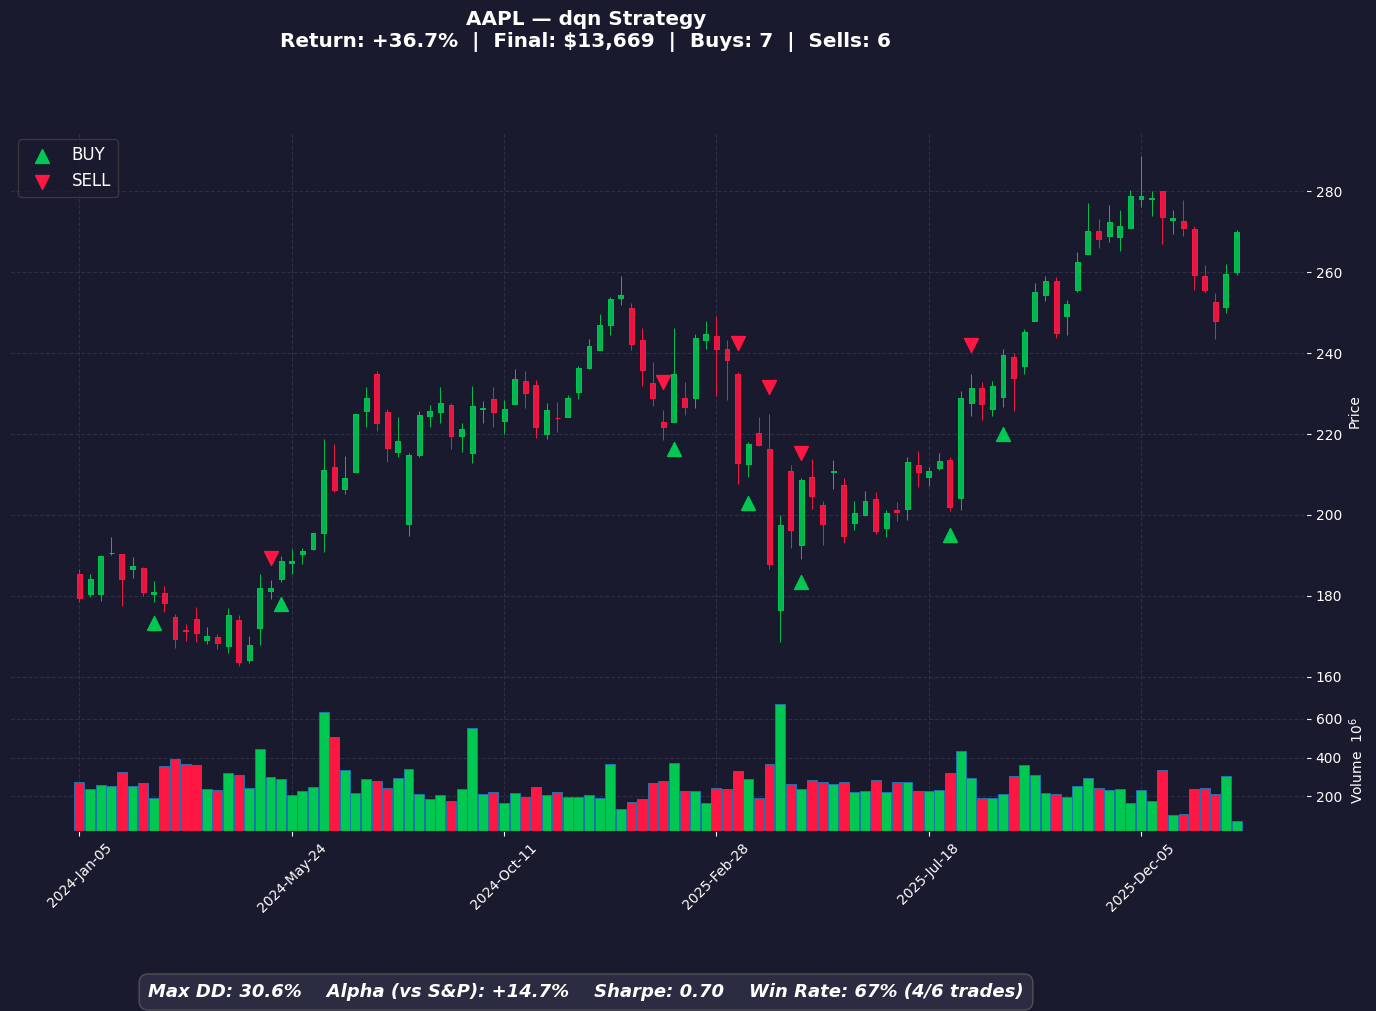

### AAPL — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$180.10,55,"$9,905.71","$9,990.09"
2024-05-13,SELL,$185.04,55,"$10,177.11","$10,251.32"
2024-05-20,BUY,$189.77,53,"$10,057.63","$10,241.26"
2025-01-27,SELL,$228.84,53,"$12,128.63","$12,300.13"
2025-02-03,BUY,$227.00,54,"$12,258.01","$12,287.87"
2025-03-17,SELL,$213.29,54,"$11,517.46","$11,535.80"
2025-03-24,BUY,$219.99,52,"$11,439.68","$11,524.36"
2025-04-07,SELL,$180.85,52,"$9,404.45","$9,479.72"
2025-04-21,BUY,$192.52,49,"$9,433.27","$9,470.29"
2025-04-28,SELL,$209.44,49,"$10,262.52","$10,289.27"


In [12]:
plot_ticker('AAPL', method='dqn')

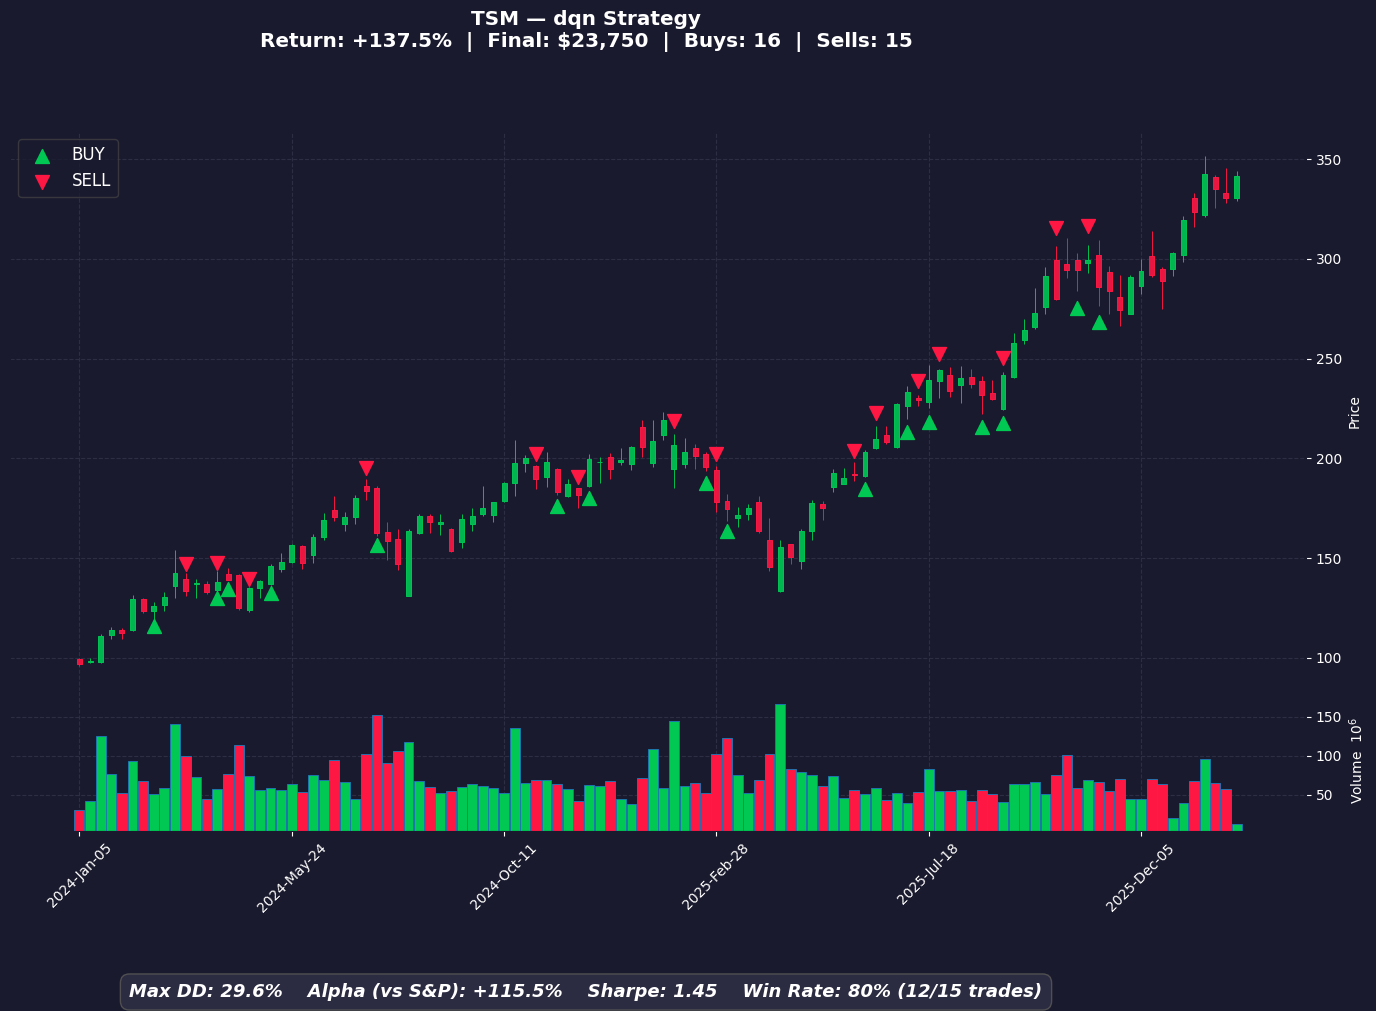

### TSM — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$127.14,78,"$9,916.62","$9,990.08"
2024-03-18,SELL,$133.51,78,"$10,414.08","$10,477.14"
2024-04-01,BUY,$138.25,75,"$10,368.97","$10,466.77"
2024-04-08,SELL,$139.52,75,"$10,464.24","$10,551.57"
2024-04-15,BUY,$136.93,76,"$10,406.97","$10,541.17"
2024-04-29,SELL,$135.33,76,"$10,285.18","$10,409.09"
2024-05-13,BUY,$143.06,72,"$10,300.35","$10,398.79"
2024-07-15,SELL,$181.55,72,"$13,071.76","$13,157.13"
2024-07-22,BUY,$166.00,79,"$13,113.72","$13,144.01"
2024-11-04,SELL,$188.45,79,"$14,887.73","$14,903.14"


In [13]:
plot_ticker('TSM', method='dqn')

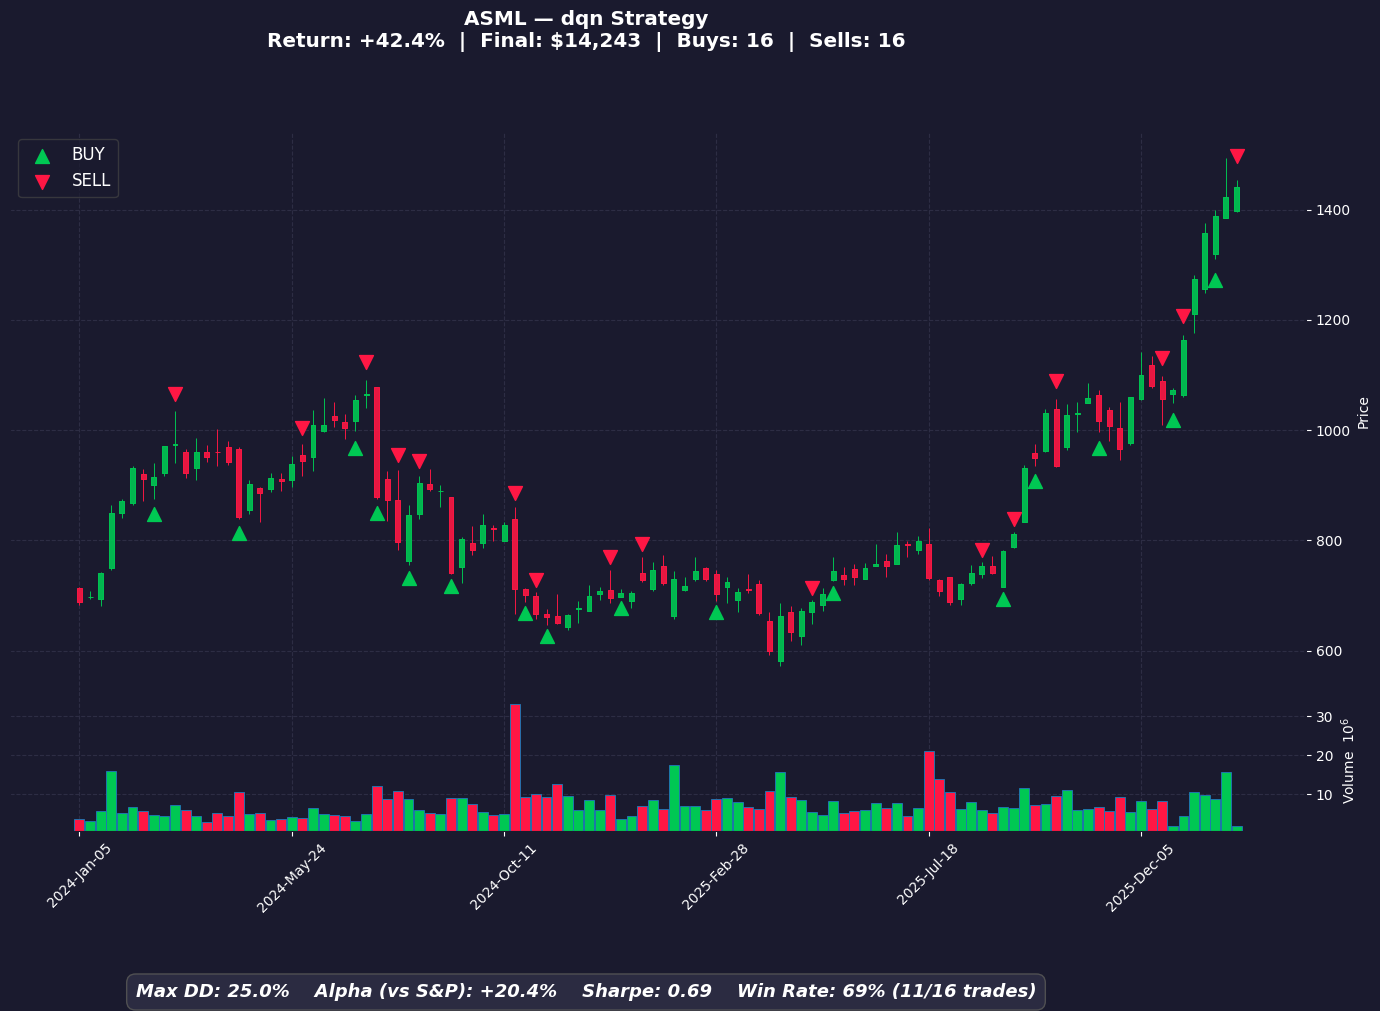

### ASML — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_29185/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$891.62,11,"$9,807.79","$9,990.19"
2024-03-11,SELL,$943.67,11,"$10,380.36","$10,552.38"
2024-04-22,BUY,$854.84,12,"$10,258.05","$10,542.12"
2024-05-28,SELL,$974.25,12,"$11,691.06","$11,963.44"
2024-07-08,BUY,"$1,058.28",11,"$11,641.05","$11,951.80"
2024-07-15,SELL,"$1,044.76",11,"$11,492.37","$11,791.63"
2024-07-22,BUY,$924.56,12,"$11,094.75","$11,780.54"
2024-08-05,SELL,$807.32,12,"$9,687.82","$10,363.92"
2024-08-12,BUY,$839.31,12,"$10,071.74","$10,353.85"
2024-08-19,SELL,$918.33,12,"$11,019.91","$11,291.00"


In [14]:
plot_ticker('ASML', method='dqn')